<a href="https://colab.research.google.com/github/anindyaa25/Project-KKA-NabilaAnindya/blob/main/SupermarketSales.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import zipfile

sns.set_style('whitegrid')

In [ ]:
import zipfile
import glob
import os

with zipfile.ZipFile(zip_name, 'r') as zip_ref:
    zip_ref.extractall('/content/dataset')

csv_files = glob.glob('/content/dataset/**/*.csv',
                      recursive=True)

print("File CSV ditemukan:", csv_files)

df = pd.read_csv(csv_files[0])

print("Dataset berhasil dibaca!")
print(df.head())

File CSV ditemukan: ['/content/dataset/supermarket_sales.csv']
Dataset berhasil dibaca!
    invoice_id branch       city customer_type gender_customer  \
0  750-67-8428      A     Yangon        Member          Female   
1  226-31-3081      C  Naypyitaw        Normal          Female   
2  631-41-3108      A     Yangon        Normal            Male   
3  123-19-1176      A     Yangon        Member            Male   
4  373-73-7910      A     Yangon        Normal            Male   

             product_line  unit_cost  quantity  5pct_markup   revenue  \
0       Health and beauty      74.69         7      26.1415  548.9715   
1  Electronic accessories      15.28         5       3.8200   80.2200   
2      Home and lifestyle      46.33         7      16.2155  340.5255   
3       Health and beauty      58.22         8      23.2880  489.0480   
4       Sports and travel      86.31         7      30.2085  634.3785   

        date   time payment_method    cogs    gm_pct  gross_income  rating  

In [ ]:
# Informasi dataset
print("INFORMASI DATASET")
df.info()

# Mengecek data kosong
print("\nDATA KOSONG")
print(df.isnull().sum())

# Mengecek data duplikat
print("\nDATA DUPLIKAT")
print(df.duplicated().sum())

# Membersihkan data
df = df.drop_duplicates()
df = df.dropna()

# Melihat ukuran dataset
print("\nUKURAN DATASET")
print(df.shape)

INFORMASI DATASET
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   invoice_id       1000 non-null   object 
 1   branch           1000 non-null   object 
 2   city             1000 non-null   object 
 3   customer_type    1000 non-null   object 
 4   gender_customer  1000 non-null   object 
 5   product_line     1000 non-null   object 
 6   unit_cost        1000 non-null   float64
 7   quantity         1000 non-null   int64  
 8   5pct_markup      1000 non-null   float64
 9   revenue          1000 non-null   float64
 10  date             1000 non-null   object 
 11  time             1000 non-null   object 
 12  payment_method   1000 non-null   object 
 13  cogs             1000 non-null   float64
 14  gm_pct           1000 non-null   float64
 15  gross_income     1000 non-null   float64
 16  rating           1000 non-null   float64
dt

In [ ]:
print("STATISTIK DESKRIPTIF")

print("\nTotal Penjualan:")
print(df['revenue'].sum())

print("\nRata-rata Transaksi:")
print(df['revenue'].mean())

print("\nMedian Transaksi:")
print(df['revenue'].median())

print("\nStandar Deviasi:")
print(df['revenue'].std())

print("\nKategori dengan Penjualan Tertinggi:")
print(df.groupby('product_line')['revenue'].sum().idxmax())

print("\nKota dengan Penjualan Tertinggi:")
print(df.groupby('city')['revenue'].sum().idxmax())

print("\nRata-rata Rating:")
print(df['rating'].mean())

STATISTIK DESKRIPTIF

Total Penjualan:
322966.749

Rata-rata Transaksi:
322.966749

Median Transaksi:
253.848

Standar Deviasi:
245.88533510097207

Kategori dengan Penjualan Tertinggi:
Food and beverages

Kota dengan Penjualan Tertinggi:
Naypyitaw

Rata-rata Rating:
6.9727


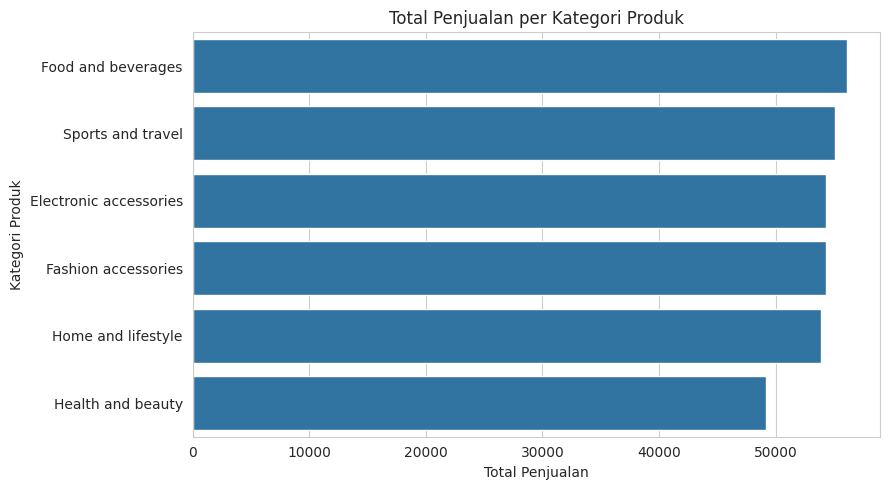

In [ ]:
total_kategori = df.groupby('product_line')['revenue'].sum().sort_values(ascending=False)

plt.figure(figsize=(9,5))

sns.barplot(
    x=total_kategori.values,
    y=total_kategori.index
)

plt.title('Total Penjualan per Kategori Produk')
plt.xlabel('Total Penjualan')
plt.ylabel('Kategori Produk')

plt.tight_layout()
plt.show()

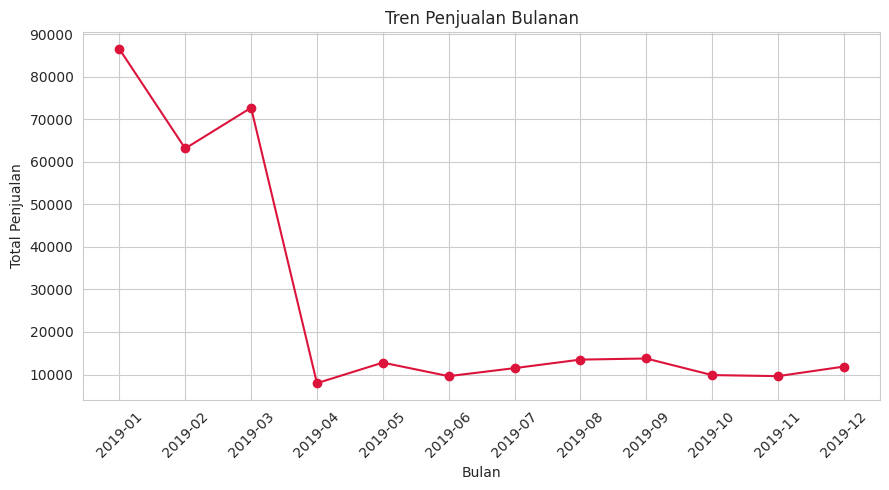

In [ ]:
# Mengubah tanggal sesuai format dataset
df['date'] = pd.to_datetime(
    df['date'],
    format='%m/%d/%y'
)

# Mengelompokkan berdasarkan bulan
df['month'] = df['date'].dt.to_period('M')

tren_bulanan = df.groupby('month')['revenue'].sum()

# Membuat grafik
plt.figure(figsize=(9,5))

plt.plot(
    tren_bulanan.index.astype(str),
    tren_bulanan.values,
    marker='o',
    color='crimson'
)

plt.title('Tren Penjualan Bulanan')
plt.xlabel('Bulan')
plt.ylabel('Total Penjualan')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Tanggal paling awal: 2019-01-01 00:00:00
Tanggal paling akhir: 2019-03-30 00:00:00


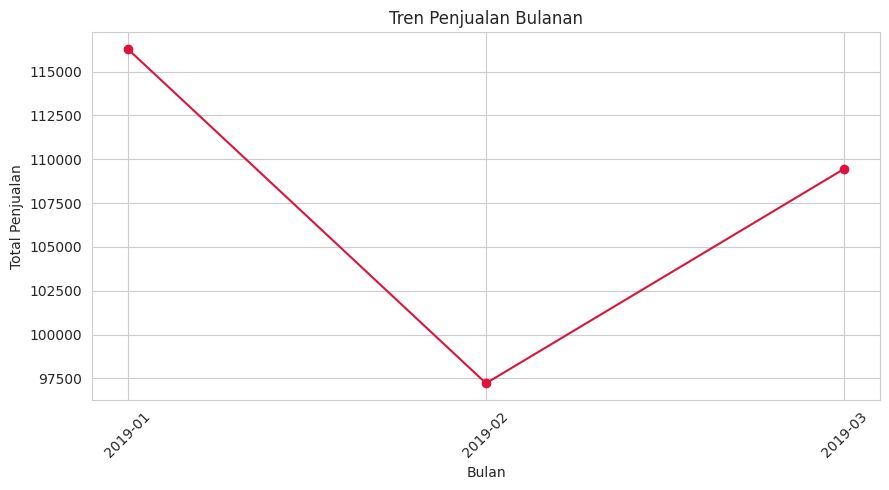

In [ ]:
# Membaca ulang dataset asli
df = pd.read_csv(csv_files[0])

# Mengubah tanggal dengan format campuran
df['date'] = pd.to_datetime(
    df['date'],
    format='mixed',
    dayfirst=False
)

# Memeriksa rentang tanggal
print("Tanggal paling awal:", df['date'].min())
print("Tanggal paling akhir:", df['date'].max())

# Mengelompokkan berdasarkan bulan
df['month'] = df['date'].dt.to_period('M')

tren_bulanan = df.groupby('month')['revenue'].sum()

# Membuat Line Chart
plt.figure(figsize=(9,5))

plt.plot(
    tren_bulanan.index.astype(str),
    tren_bulanan.values,
    marker='o',
    color='crimson'
)

plt.title('Tren Penjualan Bulanan')
plt.xlabel('Bulan')
plt.ylabel('Total Penjualan')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

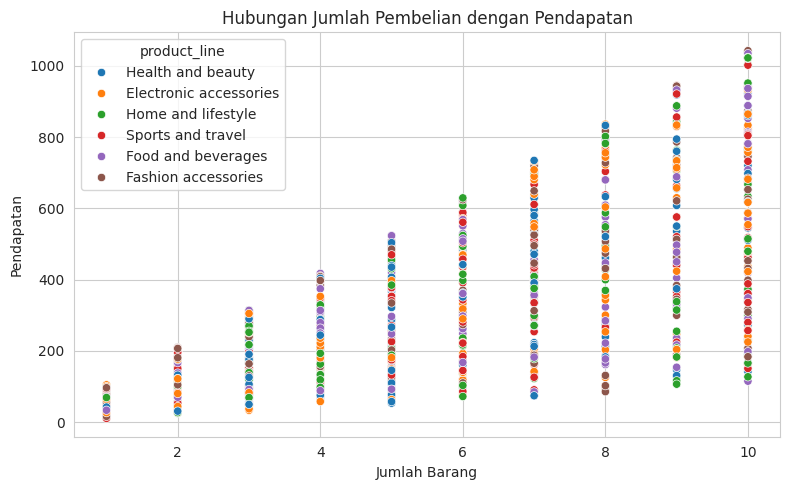

In [ ]:
plt.figure(figsize=(8,5))

sns.scatterplot(
    data=df,
    x='quantity',
    y='revenue',
    hue='product_line'
)

plt.title('Hubungan Jumlah Pembelian dengan Pendapatan')
plt.xlabel('Jumlah Barang')
plt.ylabel('Pendapatan')

plt.tight_layout()
plt.show()

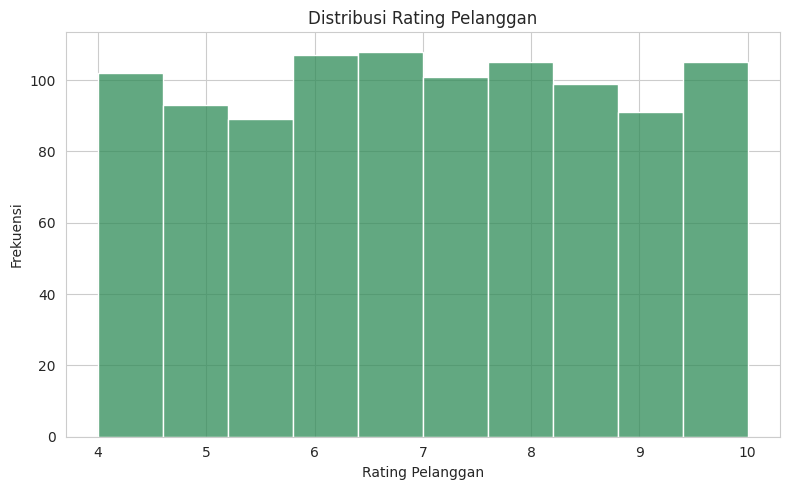

In [ ]:
plt.figure(figsize=(8,5))

sns.histplot(
    df['rating'],
    bins=10,
    color='seagreen'
)

plt.title('Distribusi Rating Pelanggan')
plt.xlabel('Rating Pelanggan')
plt.ylabel('Frekuensi')

plt.tight_layout()
plt.show()

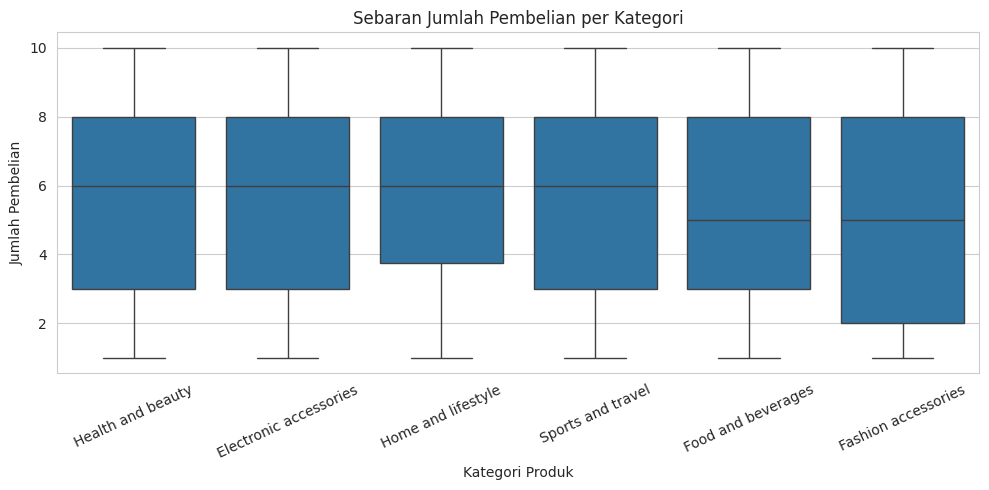

In [ ]:
plt.figure(figsize=(10,5))

sns.boxplot(
    data=df,
    x='product_line',
    y='quantity'
)

plt.title('Sebaran Jumlah Pembelian per Kategori')
plt.xlabel('Kategori Produk')
plt.ylabel('Jumlah Pembelian')

plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

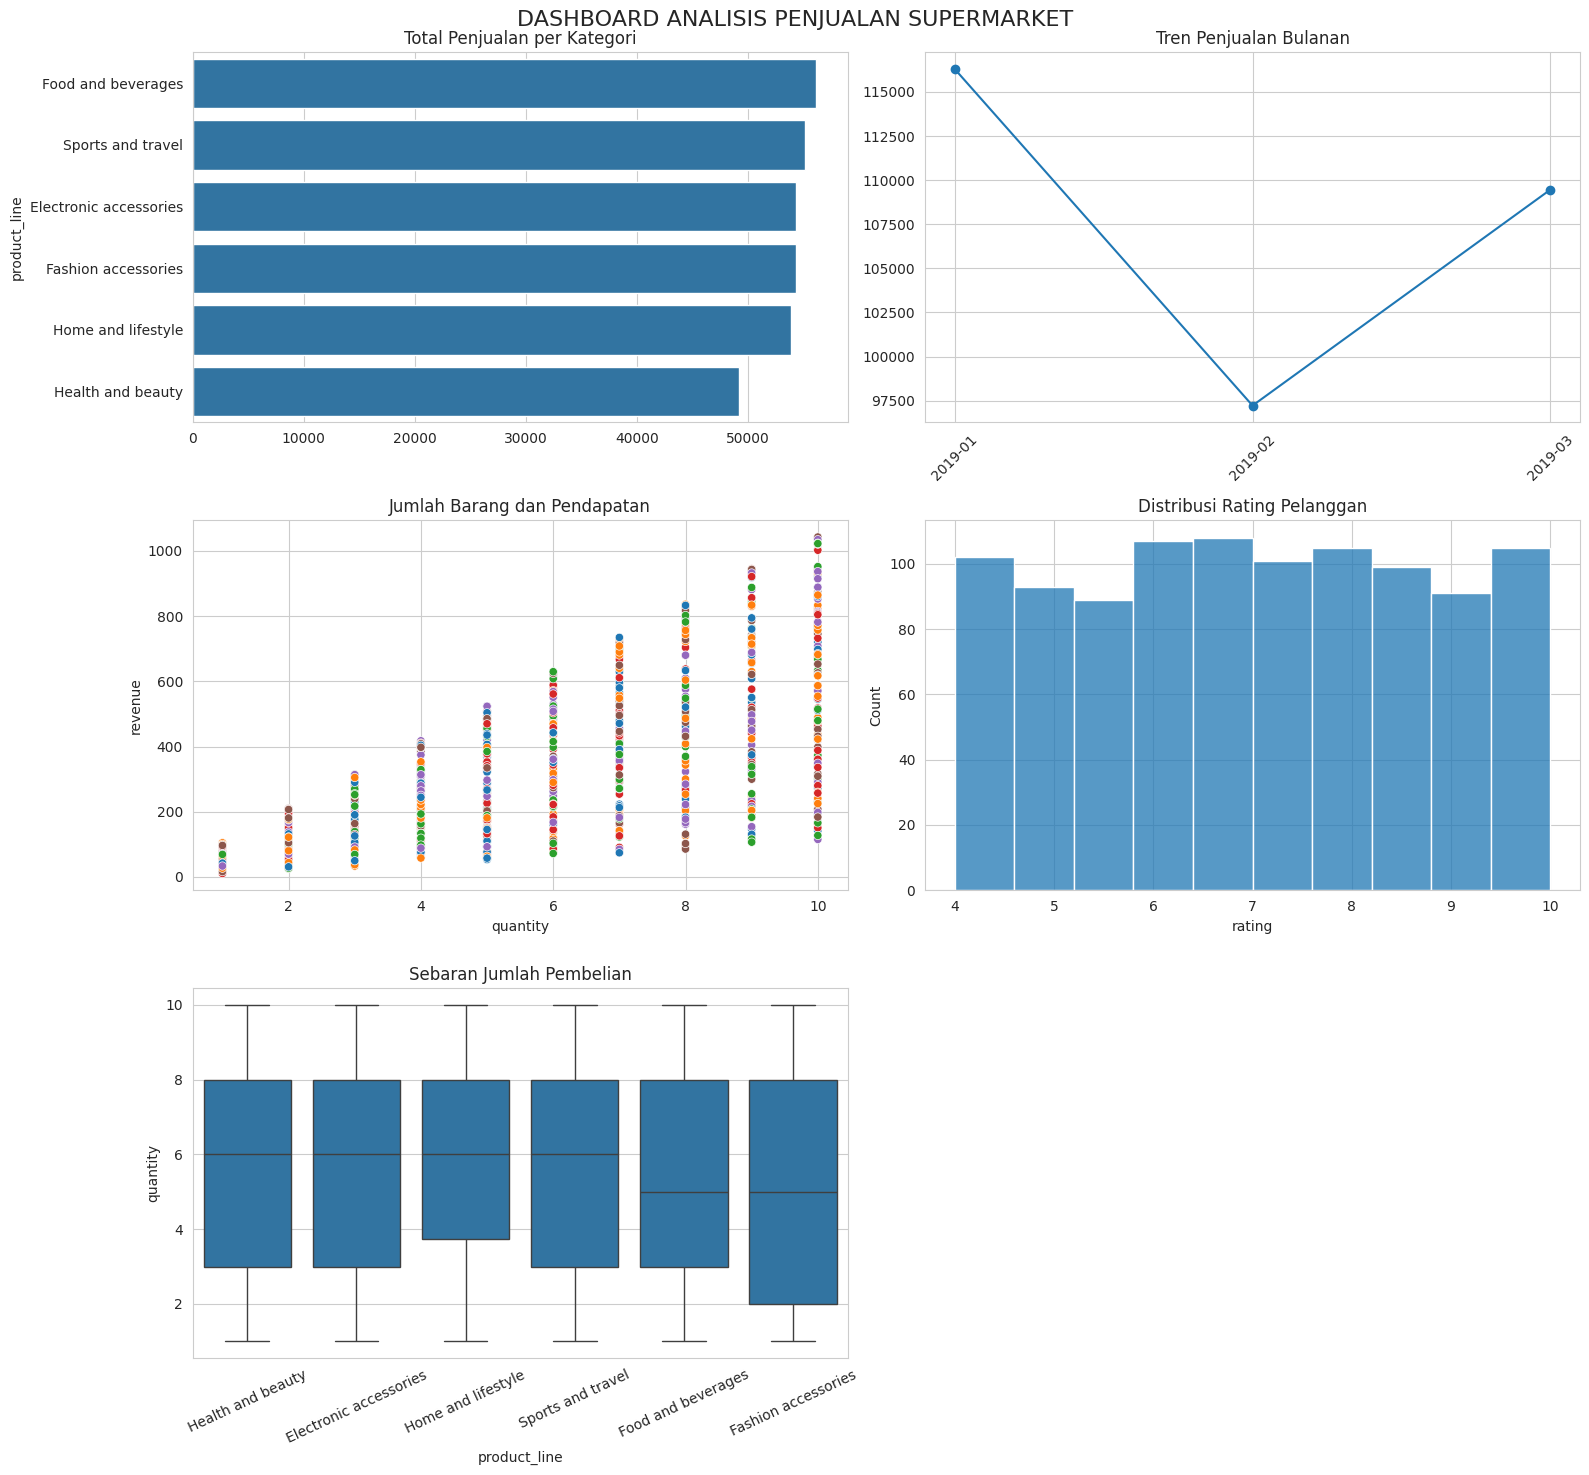

In [ ]:
fig, axes = plt.subplots(3, 2, figsize=(16, 15))

# 1. Bar Chart
sns.barplot(
    x=total_kategori.values,
    y=total_kategori.index,
    ax=axes[0,0]
)
axes[0,0].set_title('Total Penjualan per Kategori')

# 2. Line Chart
axes[0,1].plot(
    tren_bulanan.index.astype(str),
    tren_bulanan.values,
    marker='o'
)
axes[0,1].set_title('Tren Penjualan Bulanan')
axes[0,1].tick_params(axis='x', rotation=45)

# 3. Scatter Plot
sns.scatterplot(
    data=df,
    x='quantity',
    y='revenue',
    hue='product_line',
    ax=axes[1,0],
    legend=False
)
axes[1,0].set_title('Jumlah Barang dan Pendapatan')

# 4. Histogram
sns.histplot(
    df['rating'],
    bins=10,
    ax=axes[1,1]
)
axes[1,1].set_title('Distribusi Rating Pelanggan')

# 5. Boxplot
sns.boxplot(
    data=df,
    x='product_line',
    y='quantity',
    ax=axes[2,0]
)
axes[2,0].set_title('Sebaran Jumlah Pembelian')
axes[2,0].tick_params(axis='x', rotation=25)

# Menghilangkan kotak kosong
axes[2,1].axis('off')

plt.suptitle('DASHBOARD ANALISIS PENJUALAN SUPERMARKET',
             fontsize=16)

plt.tight_layout()
plt.show()